# Lecture 22, Weather types and temporal downscaling

> Sort the days into circulation types, then split a daily total into hours

This lecture follows Lee and Singh (2019), Chapter 7 (weather-type downscaling) and Chapter 8 (temporal downscaling), in the order of the book; section numbers in the headings are the book's. Lecture 16 set out the downscaling problem and Lecture 21 introduced weather generators.

- **Chapter 7, weather types.** Think of a handful of standard weather maps. Each day gets the label of the map it most resembles, and each label has its own habits of rainfall. We label the days from air pressure, then generate local daily rainfall from the labels.
- **Chapter 8, temporal downscaling.** A climate model says '40 mm fell today', but a small catchment needs to know how much fell in each hour. We split the daily total into 24 hourly values by borrowing the hourly pattern of a similar observed day.

By the end of this lecture you should be able to:

- classify a day into a weather type by the empirical (Lamb) and the objective (Jenkinson and Collison) approach,
- generate daily rainfall from a weather-type sequence: transition probabilities, rainfall occurrence, rainfall amount,
- explain how a future climate enters through the types simulated by a climate model,
- resample with the k-nearest-neighbour method (distance, k, weights) and disaggregate daily rainfall into hourly values that add up to the daily total.

**All data in this lecture are synthetic.** The workbook `data/downscaling/lec22/lec22_worked_examples.xlsx` repeats the two hand-worked examples with live formulas; the code cells print the same numbers.

### Words you need

- **Weather type**: a label for a typical weather map, for example 'anticyclonic' (high pressure, mostly dry) or 'cyclonic' (low pressure, mostly wet).
- **Transition probability**: the chance of tomorrow's type given today's type. If sunny days are followed by sunny days 7 times out of 10, the transition probability is 0.7.
- **Uniform random number** $u$: a number between 0 and 1 where every value is equally likely. We use it like a die to pick among outcomes with given chances.
- **Distance**: how different two days are. For two daily totals of 28 mm and 24 mm the distance is $(28-24)^2=16$; smaller means more alike.
- **Nearest neighbours**: the observed days with the smallest distance to the day we want. The $k$ nearest are the $k$ most similar days.
- **Weight**: the chance that a neighbour is picked. Closer neighbours get a larger weight.
- **Disaggregation**: splitting a coarse value into finer pieces, here one daily total into 24 hourly values.
- **Library**: the set of observed days (with their hourly values) from which patterns are borrowed.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas matplotlib scipy

## Notation

Symbols are those of Lee and Singh (2019). In code, Greek letters are spelled out, subscripts are joined with an underscore, and a bar or star is not used (`p_star`).

| Book symbol | Meaning | Code and spreadsheet name |
|:--|:--|:--|
| $\rho_i$, $i=1,\dots,16$ | mean sea-level pressure at grid point $i$ (hPa) | `rho` (`rho[i-1]`) |
| $\omega$, $\eta$, $F$ | westerly flow, southerly flow, resultant flow (Eqs. 7.1 to 7.3) | `omega`, `eta`, `F` |
| $Z_W$, $Z_S$, $Z$ | westerly, southerly and total shear vorticity (Eqs. 7.4 to 7.6) | `Z_W`, `Z_S`, `Z` |
| $D$ | flow direction in degrees (Eq. 7.7); the book also writes $D$ for the kNN distance | `D_flow` for the direction, `D_i` for the distance |
| LWT; A, C, W, O | weather type; anticyclonic, cyclonic, westerly, other | `types` |
| $P(\mathrm{LWT})$ | occurrence probability of each type (Table 7.3) | `P_LWT` |
| transition matrix | $\Pr$(type tomorrow, column $\mid$ type today, row) (Table 7.2) | `TM` |
| $P_{CTM}$ | cumulative probabilities used to draw the type | `PCTM` |
| $P_{wet}$, $\mu_{LWT}$ | wet-day probability and mean wet-day rainfall of a type (mm) | `P_wet`, `mu_LWT` |
| $u$, $r$ | uniform random numbers on $[0,1]$ | `u` |
| $R$ | simulated rainfall amount (mm) | `R` |
| $\mathbf{x}_i$, $\mathbf{x}_t$; $y_i$; $Y_t$ | feature vector of observation $i$ and of target time $t$; observed predictand; simulated predictand | `x_i`, `x_t`, `y_i`, `Y_t` |
| $D_i$; $w_j$; $k$; $n$; $p$ | squared distance; weight of the $j$-th nearest neighbour; number of neighbours; library length; selected index | `D_i`, `w_j`, `k`, `n`, `p` |
| $x_{i,h}$, $y_i=\sum_h x_{i,h}$ | observed hourly values and daily total of library day $i$ | `x_ih` (days by 24), `y_i` |
| $y_t$, $Y_t$, $X_{t,h}$ | target daily total (written $y_t$ in Eq. 8.3 and $Y_t$ in Eq. 8.7, the same number) and downscaled hourly values | `y_t`, `Y_t`, `X_th` |
| $P_c$, $P_m$, $\varepsilon$, $\xi$ | crossover and mutation probabilities, random number, random library day | `P_c`, `P_m`, `eps`, `xi` |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_dist

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

def read_data(name):
    # read a file of the lecture-22 data folder; fall back to GitHub if the repository is not present (Colab)
    path = "data/downscaling/lec22/" + name
    try:
        return pd.read_csv(path)
    except FileNotFoundError:
        return pd.read_csv("https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/" + path)

# 7 Weather-type downscaling

## 7.1 Classification of weather types

*In words: on a pressure map, rainy days look different from dry days (a low usually brings rain, a high usually does not). Instead of keeping every map we keep a few standard types and label each day.*

### 7.1.1 Empirical weather type

Lamb (1972) classified the days over the British Isles by eye, from surface pressure maps, winds and weather, into seven types: Anticyclonic (A), Cyclonic (C), Westerly (W), North-Westerly (NW), Northerly (N), Easterly (E) and Southerly (S). Anticyclonic days are mainly dry with light winds; cyclonic days are wet and disturbed. The result is the Lamb weather type (LWT) catalogue. Wilby (1994) used it to generate daily rainfall (Section 7.2).

### 7.1.2 Objective weather type

*'Objective' means that a computer gives the same label to the same map every time, with no human judgement.* Jones et al. (1993) automate the Jenkinson and Collison scheme with the mean sea-level pressure $\rho_i$ (hPa) at 16 grid points, $i=1,\dots,16$. The points lie on a grid with latitudes 65, 60, 55, 50, 45 degrees N: points 1 and 2 at 65N, 3 to 6 at 60N, 7 to 10 at 55N, 11 to 14 at 50N, 15 and 16 at 45N (longitudes 20W, 10W, 0, 10E; the two-point rows lie at 10W and 0). For each day the wind-flow characteristics are computed in the order of the book:

$$\omega = \tfrac12(\rho_{12}+\rho_{13}) - \tfrac12(\rho_{4}+\rho_{5})\tag{7.1}$$
$$\eta = 1.74\left[\tfrac14(\rho_5+2\rho_9+\rho_{13}) - \tfrac14(\rho_4+2\rho_8+\rho_{12})\right]\tag{7.2}$$
$$F=\sqrt{\omega^2+\eta^2}\tag{7.3}$$
$$Z_W = 1.07\left[\tfrac12(\rho_{15}+\rho_{16})-\tfrac12(\rho_8+\rho_9)\right]-0.95\left[\tfrac12(\rho_8+\rho_9)-\tfrac12(\rho_1+\rho_2)\right]\tag{7.4}$$
$$Z_S = 1.52\left[\tfrac14(\rho_6+2\rho_{10}+\rho_{14})-\tfrac14(\rho_5+2\rho_9+\rho_{13})-\tfrac14(\rho_4+2\rho_8+\rho_{12})+\tfrac14(\rho_3+2\rho_7+\rho_{11})\right]\tag{7.5}$$
$$Z=Z_W+Z_S\tag{7.6}$$

$\omega$ and $\eta$ are the westerly and southerly flows, $F$ is the resultant flow, $Z_W$ and $Z_S$ are the westerly and southerly shear vorticities, and $Z$ is the total shear vorticity. *In words: $\omega$ and $\eta$ say how strongly the air moves from west to east and from south to north (from pressure differences between the southern and northern rows, and the eastern and western columns), $F$ is the total flow strength, and $Z$ says how much the flow curls: $Z>0$ around a low, $Z<0$ around a high.* The flow direction is

$$D=\tan^{-1}(\omega/\eta),\tag{7.7}$$

taken in the quadrant that gives the direction the flow comes from. The rules of Jenkinson and Collison then define the type:

1. The W type occurs when $247.5^\circ < D < 292.5^\circ$ (other directions are treated the same way).
2. If $|Z|<F$ the flow is essentially straight and corresponds to an original Lamb type.
3. If $|Z|>2F$ the pattern is strongly cyclonic ($Z>0$) or anticyclonic ($Z<0$).
4. If $|Z|$ lies between $F$ and $2F$ the flow is partly (anti)cyclonic: a hybrid type.
5. If $F<6$ and $|Z|<6$ the flow is light and indeterminate: unclassified.

**Example 7.1 (code, new numbers).** To keep four types, as in the book's later example, we use A, C, W and **O** (all other days: other directions, hybrids, unclassified). The code builds 20 years of synthetic daily pressure at the 16 points (smooth tilt and curvature patterns with day-to-day persistence, plus noise), computes $\omega$, $\eta$, $F$, $Z_W$, $Z_S$, $Z$, $D$ for every day and applies the rules. To use real data, replace `rho` by reanalysis pressure at the 16 points. *What this means for hydrology: the types link rainfall to a circulation that climate models simulate reasonably well.*

In [3]:
rng = np.random.default_rng(22)
types = ["A", "C", "W", "O"]

def flow_indices(rho):
    # Eqs. 7.1 to 7.6; rho has the 16 grid points in its first axis
    p = lambda i: rho[i - 1]
    omega = 0.5 * (p(12) + p(13)) - 0.5 * (p(4) + p(5))
    eta = 1.74 * (0.25 * (p(5) + 2 * p(9) + p(13)) - 0.25 * (p(4) + 2 * p(8) + p(12)))
    F = np.hypot(omega, eta)
    Z_W = 1.07 * (0.5 * (p(15) + p(16)) - 0.5 * (p(8) + p(9))) - 0.95 * (0.5 * (p(8) + p(9)) - 0.5 * (p(1) + p(2)))
    Z_S = 1.52 * (0.25 * (p(6) + 2 * p(10) + p(14)) - 0.25 * (p(5) + 2 * p(9) + p(13))
                  - 0.25 * (p(4) + 2 * p(8) + p(12)) + 0.25 * (p(3) + 2 * p(7) + p(11)))
    return omega, eta, F, Z_W, Z_S, Z_W + Z_S

def weather_type(omega, eta, F, Z):
    D_flow = np.degrees(np.arctan2(-omega, -eta)) % 360            # direction the flow comes from
    t = np.full(np.shape(F), "O", dtype="<U1")
    t[(np.abs(Z) < F) & (D_flow > 247.5) & (D_flow < 292.5)] = "W"   # rules 1 and 2
    t[Z > 2 * F] = "C"; t[Z < -2 * F] = "A"                          # rule 3
    t[(F < 6) & (np.abs(Z) < 6)] = "O"                               # rule 5
    return t, D_flow

# synthetic pressure at the 16 points: 1013 hPa + north-south tilt + east-west tilt + curvature + noise
lat_i = np.array([65, 65, 60, 60, 60, 60, 55, 55, 55, 55, 50, 50, 50, 50, 45, 45])
col_i = np.array([-.5, .5, -1.5, -.5, .5, 1.5, -1.5, -.5, .5, 1.5, -1.5, -.5, .5, 1.5, -.5, .5])
y_g = (lat_i - 55) / 5.0
n_days = 20 * 365
amp = np.zeros((n_days, 3)); sd = np.array([4.0, 2.5, 0.8])
for t in range(1, n_days):
    amp[t] = 0.8 * amp[t - 1] + 0.6 * sd * rng.standard_normal(3)
rho = 1013 + amp[:, [0]] * y_g + amp[:, [1]] * col_i + amp[:, [2]] * (col_i ** 2 + y_g ** 2 - 2.5) \
      + 0.8 * rng.standard_normal((n_days, 16))                     # days by 16 points [hPa]

omega, eta, F, Z_W, Z_S, Z = flow_indices(rho.T)
typ, D_flow = weather_type(omega, eta, F, Z)
print(f"day 1: omega = {omega[0]:.2f}, eta = {eta[0]:.2f}, F = {F[0]:.2f}, Z_W = {Z_W[0]:.2f}, Z_S = {Z_S[0]:.2f}, Z = {Z[0]:.2f} hPa, "
      f"D = {D_flow[0]:.0f} deg -> type {typ[0]}")
print("type frequencies:", {s: round(float(np.mean(typ == s)), 3) for s in types})

# rainfall drawn from the classified type (the 'true' P_wet and mu_LWT the fit below should recover)
P_wet_true = np.array([0.12, 0.75, 0.55, 0.35]); mu_true = np.array([1.8, 6.0, 4.0, 3.0])
t_idx = np.array([types.index(s) for s in typ])
rain = np.where(rng.random(n_days) < P_wet_true[t_idx], -mu_true[t_idx] * np.log(1 - rng.random(n_days)), 0.0)
print(f"mean rainfall {rain.mean():.2f} mm/day, wet-day fraction {(rain > 0).mean():.2f}")

day 1: omega = -1.47, eta = 0.72, F = 1.64, Z_W = 0.79, Z_S = -1.04, Z = -0.26 hPa, D = 116 deg -> type O
type frequencies: {'A': 0.128, 'C': 0.136, 'W': 0.091, 'O': 0.646}
mean rainfall 1.52 mm/day, wet-day fraction 0.40


## 7.2 Generation of daily rainfall sequences

With the weather types of the catalogue, transition matrices and precipitation statistics can be extracted (Tables 7.2 and 7.3 of the book). Once the type of each day is known this is straightforward: count how often each type occurs, $P(\mathrm{LWT})$; how often each type follows each other type (the **transition matrix**: rows today, columns tomorrow); and for each type the fraction of wet days $P_{wet}$ and the mean rainfall on wet days $\mu_{LWT}$. The next cell does this for the running example, using the rainfall record that was drawn from the classified types (to use real data, replace `rain` by a gauge record).

In [4]:
P_LWT = np.bincount(t_idx, minlength=4) / n_days
N = np.zeros((4, 4)); np.add.at(N, (t_idx[:-1], t_idx[1:]), 1)
TM = N / N.sum(1, keepdims=True)
wet = rain > 0
P_wet = np.array([wet[t_idx == k].mean() for k in range(4)])
mu_LWT = np.array([rain[(t_idx == k) & wet].mean() for k in range(4)])
print(pd.DataFrame({"P_LWT": P_LWT, "P_wet": P_wet, "mu_LWT [mm]": mu_LWT}, index=types).round(3))
print("\ntransition matrix TM (rows today, columns tomorrow):\n", pd.DataFrame(TM, index=types, columns=types).round(3))

   P_LWT  P_wet  mu_LWT [mm]
A  0.128  0.133        1.793
C  0.136  0.765        6.004
W  0.091  0.564        3.840
O  0.646  0.350        2.944

transition matrix TM (rows today, columns tomorrow):
        A      C      W      O
A  0.481  0.005  0.030  0.483
C  0.006  0.517  0.028  0.449
W  0.047  0.053  0.460  0.440
O  0.095  0.093  0.064  0.748


A daily rainfall series is then generated as follows (Section 7.2 of the book):

1. **Chances of the type.** On the first day use the cumulative occurrence probabilities $P_{CTM}$ built from $P(\mathrm{LWT})$ in the order of the table; on later days use the cumulative probabilities of the row of the previous day's type in the transition matrix.
2. **Draw the type.** $P_{CTM}$ is a running total of the chances, like cutting the interval 0 to 1 into slices as wide as the chances. Draw a random number $u$ between 0 and 1; the slice $[P_{CTM}(j-1),\,P_{CTM}(j))$ that contains $u$ gives the type.
3. **Does it rain?** Draw a new $u$. A type with $P_{wet}=0.5$ should rain on half of its days, so the day is wet if $u < P_{wet}$ and dry otherwise.
4. **How much?** On a wet day most amounts are small and a few are large. The exponential curve has this shape (Eq. 7.8, after Wilby, 1994): $R=-\mu_{LWT}\ln(1-u)$ for a new $u$, where $\mu_{LWT}$ is the mean amount of the type.
5. Repeat steps 2 to 4 for every day.

### Worked example (by hand)

*Problem.* Types A, C, W, O have $P(\mathrm{LWT})$ = 0.30, 0.10, 0.20, 0.40, $P_{wet}$ = 0.15, 0.80, 0.50, 0.40 and $\mu_{LWT}$ = 2.0, 7.0, 4.0, 3.0 mm. The transition matrix (rows today, columns tomorrow, order A, C, W, O) is

| today \ tomorrow | A | C | W | O |
|:--|:--|:--|:--|:--|
| A | 0.50 | 0.05 | 0.10 | 0.35 |
| C | 0.10 | 0.40 | 0.10 | 0.40 |
| W | 0.15 | 0.10 | 0.45 | 0.30 |
| O | 0.20 | 0.15 | 0.15 | 0.50 |

Simulate two days with $u_1=0.34$ (type of day 1), $u_2=0.58$ (type of day 2), $u_3=0.27$ (occurrence) and $u_4=0.70$ (amount).

*Solution.*

- Day 1 (cut 0 to 1 into slices as wide as the chances). $P_{CTM}=[0.30,\ 0.30+0.10,\ 0.40+0.20,\ 0.60+0.40]=[0.30,\ 0.40,\ 0.60,\ 1.00]$. Since $0.30\le u_1=0.34<0.40$, day 1 is type **C**.
- Day 2 (now use the row of C, because the chances depend on today's type). The row of C is $[0.10,0.40,0.10,0.40]$, so $P_{CTM}=[0.10,\ 0.50,\ 0.60,\ 1.00]$. Since $0.50\le u_2=0.58<0.60$, day 2 is type **W**.
- Does it rain? (compare $u_3$ with the wet-day chance). For W, $P_{wet}=0.50$. Because $u_3=0.27<0.50$, day 2 is **wet**.
- How much? (the exponential turns $u_4$ into an amount with mean 4 mm). $\mu_{LWT}=4.0$ mm, so $R=-4.0\,\ln(1-0.70)=-4.0\times\ln(0.30)=-4.0\times(-1.2040)=4.82$ mm.

*Answer.* Day 1 is C; day 2 is W, wet, with $R=4.82$ mm. The type fixes both how likely rain is and how much falls, and the transition probabilities carry today's type into tomorrow.

In [5]:
# The same numbers as the hand example and as the WeatherType_Rain sheet of the workbook
P_LWT_ex = np.array([0.30, 0.10, 0.20, 0.40]); P_wet_ex = np.array([0.15, 0.80, 0.50, 0.40]); mu_ex = np.array([2.0, 7.0, 4.0, 3.0])
TM_ex = np.array([[0.50, 0.05, 0.10, 0.35], [0.10, 0.40, 0.10, 0.40], [0.15, 0.10, 0.45, 0.30], [0.20, 0.15, 0.15, 0.50]])
u1, u2, u3, u4 = 0.34, 0.58, 0.27, 0.70

PCTM = np.cumsum(P_LWT_ex); day1 = int(np.sum(PCTM <= u1))          # number of PCTM values <= u: index of the type
PCTM_row = np.cumsum(TM_ex[day1]); day2 = int(np.sum(PCTM_row <= u2))
wet_day = u3 < P_wet_ex[day2]
R = -mu_ex[day2] * np.log(1 - u4) if wet_day else 0.0
print("PCTM day 1:", PCTM, "-> type", types[day1])
print("PCTM day 2:", PCTM_row, "-> type", types[day2])
print(f"P_wet = {P_wet_ex[day2]}, u3 = {u3} -> {'wet' if wet_day else 'dry'}; R = {R:.3f} mm")

PCTM day 1: [0.3 0.4 0.6 1. ] -> type C
PCTM day 2: [0.1 0.5 0.6 1. ] -> type W
P_wet = 0.5, u3 = 0.27 -> wet; R = 4.816 mm



                               observed  simulated
mean annual rain [mm]           553.19     526.09
wet-day fraction                  0.40       0.39
mean wet-spell length [days]      1.76       1.79


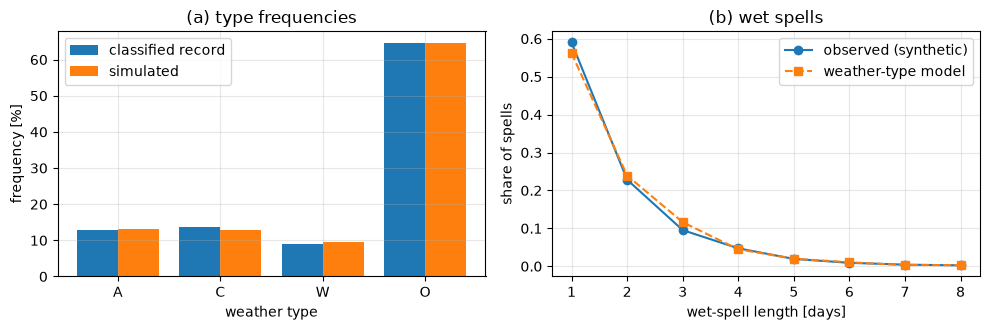

In [6]:
# The same steps for 20 years with the fitted statistics, compared with the record
def simulate(n, rng):
    PCTM_first, PCTM_rows = np.cumsum(P_LWT), np.cumsum(TM, axis=1)
    T = np.empty(n, int); Rs = np.zeros(n)
    for t in range(n):
        u = rng.random(3)
        cum = PCTM_first if t == 0 else PCTM_rows[T[t - 1]]
        T[t] = min(int(np.sum(cum <= u[0])), 3)                    # step 2: interval [PCTM(j-1), PCTM(j)) containing u
        if u[1] < P_wet[T[t]]:                                     # step 3: wet if u < P_wet
            Rs[t] = -mu_LWT[T[t]] * np.log(1 - u[2])               # step 4: exponential amount
    return T, Rs

T_sim, R_sim = simulate(n_days, np.random.default_rng(1))

def spell_lengths(w):
    edges = np.flatnonzero(np.diff(np.r_[0, w.astype(int), 0]))
    return edges[1::2] - edges[::2]
sp_obs, sp_sim = spell_lengths(rain > 0), spell_lengths(R_sim > 0)
summary = pd.DataFrame({"observed": [rain.sum() / 20, (rain > 0).mean(), sp_obs.mean()],
                        "simulated": [R_sim.sum() / 20, (R_sim > 0).mean(), sp_sim.mean()]},
                       index=["mean annual rain [mm]", "wet-day fraction", "mean wet-spell length [days]"]).round(2)
print("\n", summary)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
xk = np.arange(4)
ax[0].bar(xk - 0.2, 100 * P_LWT, 0.4, label="classified record"); ax[0].bar(xk + 0.2, 100 * np.bincount(T_sim, minlength=4) / n_days, 0.4, label="simulated")
ax[0].set_xticks(xk); ax[0].set_xticklabels(types); ax[0].set_xlabel("weather type"); ax[0].set_ylabel("frequency [%]"); ax[0].legend(); ax[0].set_title("(a) type frequencies")
L_ = np.arange(1, 9)
ax[1].plot(L_, [np.mean(sp_obs == l) for l in L_], "o-", label="observed (synthetic)"); ax[1].plot(L_, [np.mean(sp_sim == l) for l in L_], "s--", label="weather-type model")
ax[1].set_xlabel("wet-spell length [days]"); ax[1].set_ylabel("share of spells"); ax[1].legend(); ax[1].set_title("(b) wet spells")
fig.tight_layout()

The weather-type model reproduces the wet-day fraction, the annual rainfall and the wet-spell lengths. Spells last because the types last. *What this means for hydrology: generated rainfall has realistic wet and dry spells, which matter for droughts and soil moisture.*

## 7.3 Future climate with weather-type downscaling

The future evolution of daily precipitation is simulated by conditioning on the weather types obtained from global climate model (GCM) output. The steps are:

1. Obtain future circulation variables (here mean sea-level pressure) from the GCM.
2. Classify the future days with the criteria defined from the **observed** pressure, in the same way as in Section 7.1.
3. Generate the future daily precipitation with the steps of Section 7.2, using the future type sequence.

*What this means for hydrology: future rainfall changes through the types the GCM produces. A pattern that never occurred in the record can only be put into one of the existing types, most likely O.*

## 7.4 Summary and conclusion

Weather-type downscaling relates physical weather conditions to statistical downscaling through the type labels. Everything depends on the classification method. The book uses a simple empirical approach and mentions k-means, machine learning and Gaussian mixture distributions as more complex classification methods; they are not developed here.

# 8 Temporal downscaling

## 8.1 Background

### 8.1.1 k-nearest-neighbour resampling

*In words: to guess something about a new day, look at the observed days that were most like it and borrow from one of them; closer matches get a larger chance.* The k-nearest-neighbour resampling (KNNR) method was developed by Lall and Sharma (1996). We have observed pairs $(\mathbf{x}_i, y_i)$, $i=1,\dots,n$, where $\mathbf{x}_i=\{x_i^{(s)}\}$ is a vector of $S$ predictor variables and $y_i$ is the predictand. The aim is to simulate the predictand $Y_t$ at time $t$, given the predictors $\mathbf{x}_t$ and the number of neighbours $k$:

1. **Distance.** For $i=1,\dots,n$ compute the Mahalanobis distance

   $$D_i = (\mathbf{x}_t-\mathbf{x}_i)^{\mathsf T}\,C^{-1}(\mathbf{x}_t-\mathbf{x}_i),\tag{8.1}$$

   where $C$ is the covariance matrix of $\mathbf{x}$ (it only rescales the variables so that none counts more than another). With one variable this is simply the squared difference $D_i=(x_t-x_i)^2$, the only form used below.
2. **Neighbours.** Sort the distances in ascending order, keep the $k$ smallest and store their time indices.
3. **Weights.** Choose one of the $k$ stored indices at random, with the probability of the $j$-th nearest neighbour

   $$w_j=\frac{1/j}{\sum_{m=1}^{k}1/m},\qquad j=1,\dots,k.\tag{8.2}$$

   Draw a random number $u$ between 0 and 1 and take the first $j$ whose cumulative weight $\sum_{m\le j}w_m$ is at least $u$.
4. **Assign.** If the selected index is $p$, then $Y_t=y_p$.

The usual choice is $k=\lceil\sqrt n\rceil$ (the square root of $n$ rounded up; for $n=10$, $k=4$). The result is not sensitive to $k$.

**Example 8.1 (code, new numbers).** Simulate the rainfall of one month from the wind direction. The library has $n=10$ years with wind direction $x_i$ (degrees) and rainfall $y_i$ (mm), and the target is $x_t=90^\circ$.

In [7]:
x_i = np.array([93, 141, 130, 88, 106, 178, 98, 84, 160, 101.0])          # wind direction [deg]
y_i = np.array([59, 57, 54, 69, 52, 73, 49, 50, 69, 64.0])                # rainfall [mm]
x_t, u = 90.0, 0.50
n = len(x_i); k = int(np.ceil(np.sqrt(n)))                                 # k = ceil(sqrt(10)) = 4
D_i = (x_t - x_i) ** 2                                                     # one variable: squared difference
nb = np.argsort(D_i, kind="stable")[:k]                                    # indices of the k smallest distances
w_j = 1 / np.arange(1, k + 1); w_j /= w_j.sum(); cw = np.cumsum(w_j)       # Eq. 8.2
j_star = int(np.searchsorted(cw, u) + 1); p = nb[j_star - 1]               # first j with cumulative weight >= u
print(pd.DataFrame({"i": nb + 1, "x_i [deg]": x_i[nb], "D_i": D_i[nb], "y_i [mm]": y_i[nb], "w_j": w_j.round(4), "cumulative": cw.round(4)},
                   index=pd.Index(np.arange(1, k + 1), name="j")))
print(f"k = {k}; u = {u} -> j* = {j_star}, p = {p + 1}; simulated Y_t = y_p = {y_i[p]:.0f} mm")

   i  x_i [deg]   D_i  y_i [mm]   w_j  cumulative
j                                                
1  4       88.0   4.0      69.0  0.48        0.48
2  1       93.0   9.0      59.0  0.24        0.72
3  8       84.0  36.0      50.0  0.16        0.88
4  7       98.0  64.0      49.0  0.12        1.00
k = 4; u = 0.5 -> j* = 2, p = 1; simulated Y_t = y_p = 59 mm


## 8.2 Daily to hourly downscaling

Hourly series are needed for medium and small watersheds, but many records and climate models give only daily values. Hourly series can be created from daily series with disaggregation rules that preserve the diurnal cycle and the additive condition (the 24 hours add up to the daily total). The nonparametric method of Lee and Jeong (2014) uses KNNR and a genetic-algorithm (GA) mixing step. *In words: on a day with 28 mm the rain probably fell in the same hours as on an observed day with a similar total, so we borrow that day's hourly shape and rescale it to 28 mm.*

The library has $n$ observed wet days (days without rain are left out) with hourly values $\mathbf{x}_i=[x_{i,1},\dots,x_{i,24}]$ and daily total $y_i=\sum_{h=1}^{24}x_{i,h}$. The target daily totals $y_t$ are known, and the aim is the hourly series $\mathbf{X}_t=[X_{t,1},\dots,X_{t,24}]$. With $k$ known, the steps are:

1. **Distance** between the target daily total and each observed daily total: $D_i=(y_t-y_i)^2$ (Eq. 8.3).
2. **Sort** the distances, keep the $k$ smallest and store their time indices.
3. **Weights.** Choose one stored index at random with the probability $w_j=\dfrac{1/j}{\sum_{m=1}^{k}1/m}$, $j=1,\dots,k$ (Eq. 8.4), by the cumulative-weight rule of Section 8.1.1.
4. **Assign** the hourly values of the selected index $p$: $\mathbf{x}_p=[x_{p,h}]$, $h=1,\dots,24$.
5. **GA mixing.** (5.1) *Reproduction:* select one more index $p^*$ with steps 1 to 3, giving $\mathbf{x}_{p^*}$. (5.2) *Crossover:* replace each hour of $\mathbf{x}_p$ by the same hour of $\mathbf{x}_{p^*}$ with probability $P_c$: $X^*_{t,h}=x_{p^*,h}$ if $\varepsilon<P_c$, otherwise $x_{p,h}$ (Eq. 8.5). (5.3) *Mutation:* replace each hour by the same hour of a library day $\xi$ chosen at random among all $n$ days, with probability $P_m$: $X^*_{t,h}=x_{\xi,h}$ if $\varepsilon<P_m$ (Eq. 8.6). Here $\varepsilon$ is a new uniform random number for every hour. In practice $P_c=0.1$ and $P_m=0.01$. *The mixing only adds variety to the borrowed pattern.*
6. **Adjust** the mixed hourly values to keep the additive condition:

   $$X_{t,h}=X^*_{t,h}\,\frac{Y_t}{\sum_{j=1}^{24}X^*_{t,j}}\tag{8.7}$$

   where $Y_t$ is the target daily total (the book writes it $y_t$ in Eq. 8.3 and $Y_t$ here). *Dividing by the sum of the hours makes the 24 hours add up to $Y_t$ exactly.*
7. **Repeat** steps 1 to 6 for every day to be generated.

**Example 8.2 (by hand, new numbers).**

*Problem.* A library of $n=6$ wet days has daily totals $y_i$ = 12, 31, 24, 8, 40, 19 mm for $i=1,\dots,6$. Downscale the target $y_t=28$ mm with $u=0.70$ and no mixing ($P_c=P_m=0$). Hourly values of library day 3 (hours not listed are 0): hours 7 to 12 are 1.5, 4.5, 7.5, 5.0, 3.0, 1.5 mm and hours 19 and 20 are 0.6 and 0.4 mm.

*Solution.*

1. How alike is each day? Distances $D_i=(28-y_i)^2$: $D_1=16^2=256$, $D_2=3^2=9$, $D_3=4^2=16$, $D_4=20^2=400$, $D_5=12^2=144$, $D_6=9^2=81$. The number of neighbours is $k=\lceil\sqrt6\rceil=\lceil2.449\rceil=3$.
2. Keep the closest three. Sorted: 9 ($i=2$), 16 ($i=3$), 81 ($i=6$), so $j=1,2,3\to i=2,3,6$.
3. Closer days get larger chances (weights proportional to $1/j$, so 1, 1/2, 1/3, divided by their sum so that they total 1). $\sum_{m=1}^{3}1/m=1+0.5+0.3333=1.8333$, so $w_1=0.5455$, $w_2=0.2727$, $w_3=0.1818$. Cumulative: 0.5455, 0.8182, 1.0000. The random number $u=0.70$ lies in $(0.5455,\,0.8182]$, so $j^*=2$ and $p=3$ with $y_p=24$ mm.
4. The hourly values of day 3 are as listed (check: $1.5+4.5+7.5+5.0+3.0+1.5+0.6+0.4=24.0$).
5. No mixing, so $X^*_{t,h}=x_{3,h}$.
6. Rescale to the target: $X_{t,h}=x_{3,h}\times28/24=x_{3,h}\times1.1667$. Hour 7 gives 1.75, hour 8 gives 5.25, hour 9 gives 8.75, hour 10 gives 5.83, hour 11 gives 3.50, hour 12 gives 1.75, hour 19 gives 0.70 and hour 20 gives 0.47 mm. Check that the hours add up: $1.75+5.25+8.75+5.83+3.50+1.75+0.70+0.47=28.0$ mm.

*Answer.* The 28 mm day gets the pattern of day 3, scaled by 1.1667, with its largest hour 8.75 mm in hour 9. The daily total is kept exactly. *What this means for hydrology: the hourly peak decides flooding in small catchments, and a daily total alone hides it.*

k = 3  D_i = [256.   9.  16. 400. 144.  81.]  neighbours (day numbers) = [2 3 6]
w_j = [0.5455 0.2727 0.1818]  cumulative = [0.5455 0.8182 1.    ]  -> j* = 2 , p = 3 (y_p = 24 mm)
X_th at hours 7-12: [1.75 5.25 8.75 5.83 3.5  1.75]  hours 19-20: [0.7  0.47]
sum of the 24 hours = 28.00 mm; largest hour 8.75 mm


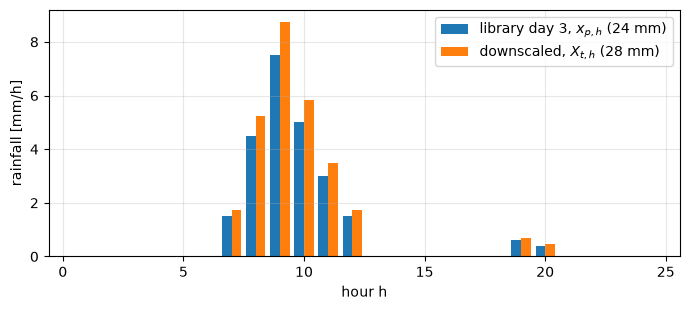

In [8]:
# The same numbers as the hand example and as the kNN_Resample sheet of the workbook
lib = read_data("knn_library_hourly.csv")
x_ih = lib.iloc[:, 1:].to_numpy(); y_i = x_ih.sum(1)
y_t = Y_t = 28.0; u = 0.70
n = len(y_i); k = int(np.ceil(np.sqrt(n)))
D_i = (y_t - y_i) ** 2
nb = np.argsort(D_i, kind="stable")[:k]                          # neighbours j = 1..k (library rows)
w_j = (1 / np.arange(1, k + 1)); w_j /= w_j.sum(); cw = np.cumsum(w_j)
j_star = int(np.searchsorted(cw, u) + 1)                         # first j with cumulative weight >= u
p = nb[j_star - 1]
X_th = x_ih[p] * Y_t / x_ih[p].sum()                             # Eq. 8.7 with X* = x_p
print("k =", k, " D_i =", D_i, " neighbours (day numbers) =", nb + 1)
print("w_j =", w_j.round(4), " cumulative =", cw.round(4), " -> j* =", j_star, ", p =", p + 1, f"(y_p = {y_i[p]:.0f} mm)")
print("X_th at hours 7-12:", X_th[6:12].round(2), " hours 19-20:", X_th[18:20].round(2))
print(f"sum of the 24 hours = {X_th.sum():.2f} mm; largest hour {X_th.max():.2f} mm")

fig, ax = plt.subplots(figsize=(7, 3.2))
hh = np.arange(1, 25)
ax.bar(hh - 0.2, x_ih[p], 0.4, label=f"library day {p+1}, $x_{{p,h}}$ ({y_i[p]:.0f} mm)"); ax.bar(hh + 0.2, X_th, 0.4, label=f"downscaled, $X_{{t,h}}$ ({Y_t:.0f} mm)")
ax.set_xlabel("hour h"); ax.set_ylabel("rainfall [mm/h]"); ax.legend(); fig.tight_layout()

### Applying the method to a longer record

Now we test the full method, with mixing, on a longer record, where we know the right answer. We build 40 summers (122 days, June to September) of hourly rainfall: a two-state Markov chain makes active and break spells, storms start mostly in the afternoon, and each storm has a gamma depth, a duration that grows with depth and a skewed hump-shaped intensity profile. Values are rounded to 0.1 mm. The first 20 years form the library of observed days; the last 20 years play the role of the truth that we try to recover from their daily totals alone. To use real data, load an hourly gauge record, reshape it to days by 24 hours and split it in the same way.

In [9]:
def make_hourly(n_years=40, days=122, seed=7):
    rg = np.random.default_rng(seed)
    nd = n_years * days
    H = np.zeros(nd * 24 + 48)
    regime = np.zeros(nd, int)
    for d in range(1, nd):                                   # active (1) / break (0) spells
        stay = 0.85 if regime[d - 1] == 1 else 0.80
        regime[d] = regime[d - 1] if rg.random() < stay else 1 - regime[d - 1]
    rate = np.where(regime == 1, 1.1, 0.25)                  # storms per day
    for d in range(nd):
        for _ in range(rg.poisson(rate[d])):
            s = (rg.normal(17, 2.5) if rg.random() < 0.65 else rg.uniform(0, 24)) % 24    # start hour
            depth = rg.gamma(0.8, 14.0)                      # storm depth [mm]
            dur = max(0.7, 0.8 * depth ** 0.5 * rg.lognormal(0, 0.45))                    # duration [h]
            a, b = rg.uniform(1.0, 2.5), rg.uniform(1.0, 3.5)                             # profile shape
            t0 = d * 24 + s
            edges = np.arange(np.floor(t0), np.ceil(t0 + dur) + 1)
            frac = np.diff(beta_dist.cdf(np.clip((edges - t0) / dur, 0, 1), a, b))        # share of the storm in each hour
            H[int(edges[0]): int(edges[0]) + len(frac)] += depth * frac
    return np.round(H[: nd * 24], 1).reshape(nd, 24)

dpy = 122
Hh = make_hourly()
H_lib, H_test = Hh[: 20 * dpy], Hh[20 * dpy:]                # library years and test years (days by 24 hours)
wet_lib = H_lib.sum(1) > 0
x_ih, y_i = H_lib[wet_lib], H_lib[wet_lib].sum(1)            # library of wet days
Y_test = H_test.sum(1)                                       # target daily totals [mm]
print(f"library: {len(y_i)} wet days (k = {int(np.ceil(np.sqrt(len(y_i))))}); test: {len(Y_test)} days, {np.sum(Y_test > 0)} wet")
print(f"wet-hour fraction (>= 0.1 mm) in the test years: {(H_test >= 0.1).mean():.3f}; wettest hour {H_test.max():.1f} mm")

library: 1250 wet days (k = 36); test: 2440 days, 1191 wet
wet-hour fraction (>= 0.1 mm) in the test years: 0.088; wettest hour 51.1 mm


largest error of a daily total after downscaling: 1.42e-14 mm


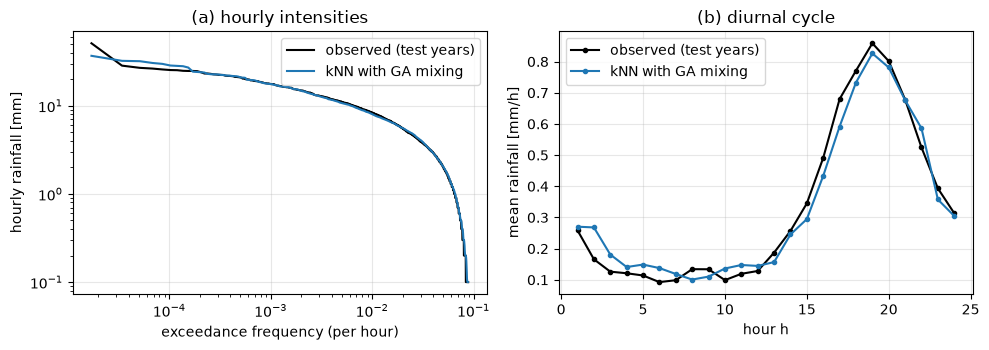

In [10]:
def disaggregate(Y, y_i, x_ih, rng, P_c=0.1, P_m=0.01):
    # kNN daily-to-hourly downscaling with GA mixing (steps 1 to 5 of Section 5)
    n = len(y_i); k = int(np.ceil(np.sqrt(n)))
    cw = np.cumsum(1 / np.arange(1, k + 1)); cw /= cw[-1]       # cumulative weights, Eq. 8.4
    def select(y_t):
        D_i = (y_t - y_i) ** 2                                   # Eq. 8.3
        nb = np.argsort(D_i, kind="stable")[:k]
        return nb[min(int(np.searchsorted(cw, rng.random())), k - 1)]
    X_th = np.zeros((len(Y), 24)); h24 = np.arange(24)
    for t in np.where(Y > 0)[0]:
        p, p_star = select(Y[t]), select(Y[t])
        X = x_ih[p].copy()
        cross = rng.random(24) < P_c; X[cross] = x_ih[p_star][cross]                   # crossover, Eq. 8.5
        mut = rng.random(24) < P_m; xi = rng.integers(n, size=24); X[mut] = x_ih[xi[mut], h24[mut]]   # mutation, Eq. 8.6 (P_m)
        if X.sum() == 0: X = x_ih[p].copy()                      # all hours zero after mixing: keep the borrowed pattern
        X_th[t] = X * Y[t] / X.sum()                             # adjustment, Eq. 8.7
    return X_th

X_sim = disaggregate(Y_test, y_i, x_ih, np.random.default_rng(3))
print(f"largest error of a daily total after downscaling: {np.abs(X_sim.sum(1) - Y_test).max():.2e} mm")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for H, lab, c in [(H_test, "observed (test years)", "k"), (X_sim, "kNN with GA mixing", "tab:blue")]:
    q = np.sort(H[H >= 0.1].ravel())[::-1]
    ax[0].loglog(np.arange(1, len(q) + 1) / H.size, q, color=c, label=lab)
    ax[1].plot(np.arange(1, 25), H.mean(0), color=c, marker="o", ms=3, label=lab)
ax[0].set_xlabel("exceedance frequency (per hour)"); ax[0].set_ylabel("hourly rainfall [mm]"); ax[0].legend(); ax[0].set_title("(a) hourly intensities")
ax[1].set_xlabel("hour h"); ax[1].set_ylabel("mean rainfall [mm/h]"); ax[1].legend(); ax[1].set_title("(b) diurnal cycle")
fig.tight_layout()

Two checks are enough here. First, every downscaled day adds up to its daily total (the largest error printed above is of the order of rounding). Second, the downscaled hourly series should look like the observed one. Figure (a) shows that the heavy hours, which are rare, are about as large and as frequent as observed (the very largest hours are slightly too small, because a borrowed pattern is rescaled but never exceeds what the library holds). Figure (b) shows that the afternoon peak of rainfall is recovered. **What this means for hydrology:** the downscaled series can be used where hourly rain is needed, for example to drive a small-catchment model, but the daily total itself must already be right (Lecture 18 corrects a biased daily series).

## 8.3 Summary and conclusion (with the summary of Chapter 7)

- A **weather type** is a recurring circulation pattern. Lamb types are assigned by eye; the Jenkinson and Collison rules compute them from the pressure at 16 grid points through $\omega$, $\eta$, $F$ and $Z$.
- Daily rainfall given the types is generated from $P(\mathrm{LWT})$ and the transition matrix (the type, through the cumulative $P_{CTM}$), then occurrence ($u<P_{wet}$) and the exponential amount with mean $\mu_{LWT}$. A future climate enters through the types simulated by the GCM, classified with the observed criteria.
- **kNN resampling** picks one of the $k=\lceil\sqrt n\rceil$ nearest observations with weights $w_j=(1/j)/\sum_m(1/m)$.
- **Daily to hourly:** match the daily total ($D_i=(y_t-y_i)^2$), borrow an hourly pattern, optionally mix it by crossover ($P_c$) and mutation ($P_m$), and scale it by $Y_t/\sum_jX^*_{t,j}$ so that the 24 hours add up to the daily total.

### Check your understanding

1. Type O has the transition row 0.20, 0.15, 0.15, 0.50 (to A, C, W, O). Which type follows O for $u=0.62$? If tomorrow is type C with $P_{wet}=0.80$ and a new $u=0.85$, is it wet?
2. With $k=4$, write the weights $w_j\propto1/j$ and their cumulative values. Which neighbour is selected for $u=0.50$ and for $u=0.90$?
3. A library day has 20 mm and an hourly maximum of 8 mm; the target day has 35 mm. Give the scale factor and the downscaled hourly maximum.

### Try it yourself

1. In the workbook change the target `y_t` on `kNN_Resample` to 8 mm and to 45 mm, and the random number `u`. Which day is chosen and how does the scale factor change?
2. In the workbook change $P_{wet}$ of type W on `Data` to 0.20. What happens to the day-2 result?
3. Run `disaggregate` with `P_c = P_m = 0` and with `P_c = 0.3`. How do the hourly intensities in Figure (a) change?

```{note} Where this lecture differs from the book
- Example 7.2 reads the occurrence inequality as $P_{wet}<u$ (wet); the lecture uses the correct direction, wet if $u<P_{wet}$.
- Table 7.2, row C, sums to 0.55; the lecture uses an assumed matrix whose rows sum to 1.
- Eq. 7.8 as printed is garbled and its example number does not reproduce; the lecture uses the exponential amount $R=-\mu_{LWT}\ln(1-u)$.
- Eq. 7.7: the 180 degree rule is applied so that $D$ is the direction the flow comes from (atan2), which differs from the printed rule for $\omega>0$, $\eta<0$.
- Eq. 8.6 prints $P_c$ where the mutation probability $P_m$ is meant; Table 8.1 labels precipitation in degrees C, but the unit is mm.
```

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. The methods follow Lee, T., & Singh, V. P. (2019). *Statistical Downscaling for Hydrological and Environmental Applications*. CRC Press: Chapter 7 (Sections 7.1 to 7.3: Lamb and Jenkinson and Collison weather types, daily rainfall generation, future climate) and Chapter 8 (Section 8.1.1: kNN resampling; Section 8.2: daily to hourly downscaling with GA mixing). The data, examples, figures and code are original to this lecture; no data from the book are used. The workbook and the CSV file in `data/downscaling/lec22/` are synthetic.

**Methods.** Lamb, H. H. (1972). British Isles weather types and a register of the daily sequence of circulation patterns 1861-1971. *Geophysical Memoir 116*, HMSO. &middot; Jones, P. D., Hulme, M., & Briffa, K. R. (1993). A comparison of Lamb circulation types with an objective classification scheme. *International Journal of Climatology, 13*, 655-663. &middot; Wilby, R. L. (1994). Stochastic weather type simulation for regional climate change impact assessment. *Water Resources Research, 30*, 3395-3403. &middot; Lall, U., & Sharma, A. (1996). A nearest neighbor bootstrap for resampling hydrologic time series. *Water Resources Research, 32*, 679-693. &middot; Lee, T., & Jeong, C. (2014). Nonparametric statistical temporal downscaling of daily precipitation to hourly precipitation and implications for climate change scenarios. *Journal of Hydrology, 510*, 182-196.

See Lecture 21 for weather generators, Lecture 18 for bias correction of the daily input, and Lecture 23 for spatial downscaling.
```